In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [2]:
df = pd.read_csv('ecg.csv', header=None)

print(df.shape)
df.head()

(4998, 141)


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [3]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_normal = x_train[y_train == 0]

print(x_train.shape)
print(x_test.shape)

(3998, 140)
(1000, 140)


In [4]:
input_dim = x_train.shape[1]

autoencoder = Sequential([
    Input(shape=(input_dim,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(8, activation='relu'),
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(input_dim, activation='linear')
])

autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,868 (89.33 KB)

 Trainable params: 22,868 (89.33 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [6]:
history = autoencoder.fit(
    train_normal,
    train_normal,
    epochs=10,
    batch_size=32,
    shuffle=True,
    validation_split=0.2
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 1.0511 - mae: 0.7417 - val_loss: 0.7226 - val_mae: 0.5874
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.6263 - mae: 0.5197 - val_loss: 0.4944 - val_mae: 0.4525
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.4458 - mae: 0.4195 - val_loss: 0.3631 - val_mae: 0.3777
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3447 - mae: 0.3578 - val_loss: 0.3193 - val_mae: 0.3474
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3124 - mae: 0.3378 - val_loss: 0.3043 - val_mae: 0.3388
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2968 - mae: 0.3288 - val_loss: 0.2956 - val_mae: 0.3354
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2877 - mae: 0.3262 - val_loss: 0.2871 - val_mae: 0.3313
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2785 - mae: 0.3215 - val_loss: 0.2844 - val_mae: 0.3304
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2703 - m

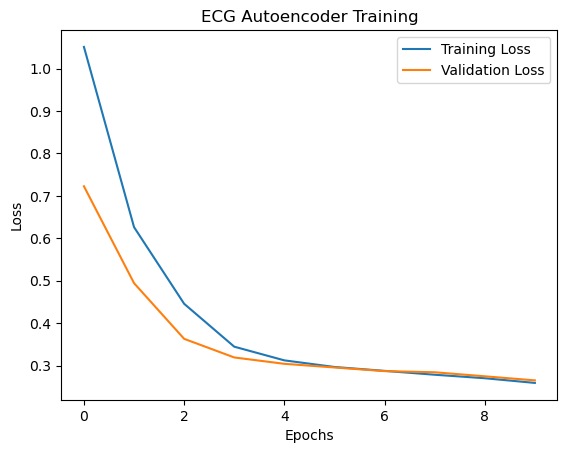

In [7]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('ECG Autoencoder Training')
plt.legend()
plt.show()

In [8]:
reconstructions = autoencoder.predict(x_test)

mse = np.mean(np.square(x_test - reconstructions), axis=1)

print(mse[:10])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
[0.15398741 0.11177735 1.53347217 0.42827333 0.58600669 0.83729013
 0.12024065 0.12127538 0.24996407 0.33343496]


In [9]:
train_predictions = autoencoder.predict(train_normal)

train_mse = np.mean(
    np.square(train_normal - train_predictions), axis=1
)

threshold = np.percentile(train_mse, 95)

print("Threshold:", threshold)

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Threshold: 0.7452577228983744


In [10]:
predictions = mse > threshold

print("Total Samples:", len(x_test))
print("Anomalies Detected:", np.sum(predictions))
print("Normal Samples:", np.sum(~predictions))

Total Samples: 1000
Anomalies Detected: 117
Normal Samples: 883


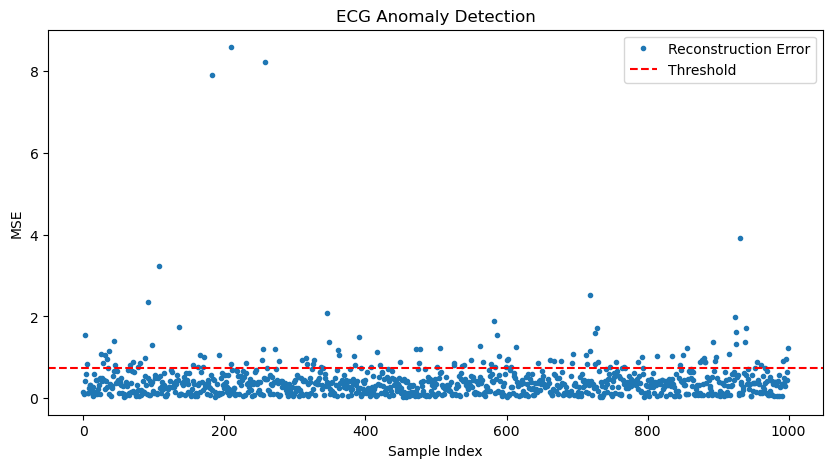

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(mse, '.', label='Reconstruction Error')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

plt.xlabel('Sample Index')
plt.ylabel('MSE')
plt.title('ECG Anomaly Detection')
plt.legend()
plt.show()